In [ ]:
import sys
import pathlib

sys.path.append("../src/ome_tiff_processing/")

from image.image import OmeTiffFile
from image.selection import ROISelectionTool

In [2]:
leica_pyramidal_image = "../data/Leica1_36832_38432_1_3_1.ome.tiff"
tif = OmeTiffFile(leica_pyramidal_image)

reference_image = tif.sel(image=1, level=4, output_shape=list("XYS"))

In [3]:
roi_tool = ROISelectionTool(tif[1])

roi_tool.serve(reference_level=4,)

ROI selector running at http://127.0.0.1:8050


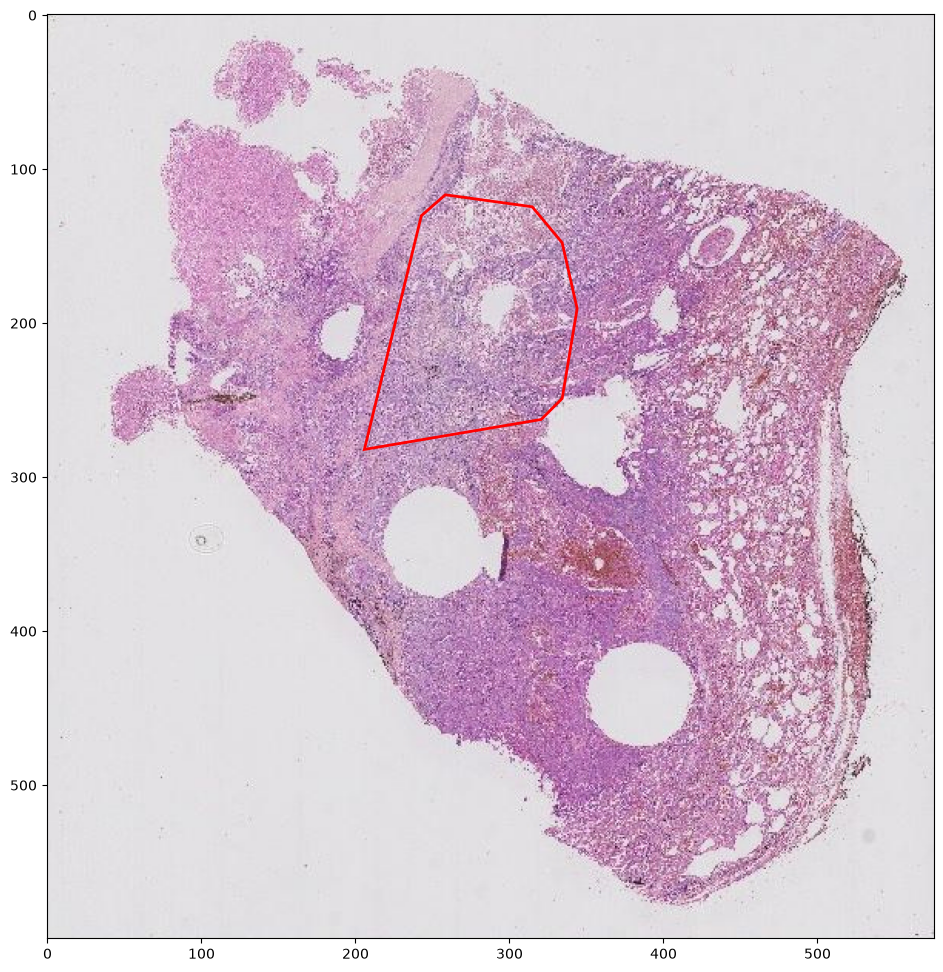

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

image = tif[1].sel(
    level=3,
    output_shape=("Y", "X", "S")
)

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(image)

polygons = roi_tool.get_polygons(target_level=3)

for polygon in polygons:
    ax.add_patch(Polygon(
        polygon,
        closed=True,
        fill=False,
        edgecolor="red",
        linewidth=2
    ))

plt.show()